### Đang review

# 03. Purchase & Basket Behavior

> Hiểu household mua bao nhiêu lần, mỗi basket có quy mô và giá trị thế nào, tổng chi tiêu hình thành ra sao, household sử dụng store và discount như thế nào.

Notebook chỉ điều phối và hiển thị biểu đồ. Toàn bộ logic tổng hợp và trực quan hóa nằm trong `src/propensity/eda`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / "src").exists():
    project_root = project_root.parent
src_dir = str(project_root / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from propensity.eda import build_transaction_behavior_tables
from propensity.eda.dunnhumby import DUNNHUMBY_TRANSACTION_PROFILE_CONFIG
from propensity.eda.visualization import (
    plot_basket_size_value_structure,
    plot_behavioral_patterns,
    plot_cross_behavior,
    plot_household_spending,
    plot_purchase_frequency,
    plot_store_usage,
    plot_transaction_discount_usage,
)
from propensity.io import scan_csv
from propensity.schema.dunnhumby import TRANSACTION_SCHEMA_OVERRIDES

## 1. Prepare Analytical Tables

Tạo hai bảng tái sử dụng: một dòng trên mỗi basket và một dòng trên mỗi household. Notebook không hiển thị bảng thống kê; các bảng này chỉ là đầu vào cho biểu đồ.

In [2]:
data_dir = project_root / "data" / "raw" / "Dunnhumby"
transactions = scan_csv(
    data_dir / "transaction_data.csv",
    schema_overrides=TRANSACTION_SCHEMA_OVERRIDES,
)
products = scan_csv(data_dir / "product.csv")
behavior = build_transaction_behavior_tables(
    transactions,
    products,
    DUNNHUMBY_TRANSACTION_PROFILE_CONFIG,
)

## 2. Purchase Frequency

Frequency là số basket distinct của household trong cùng observation window. Biểu đồ log-scale giữ được cả phần lớn household điển hình và đuôi mua rất thường xuyên mà không chuyển sang cycle/regularity của file 04.

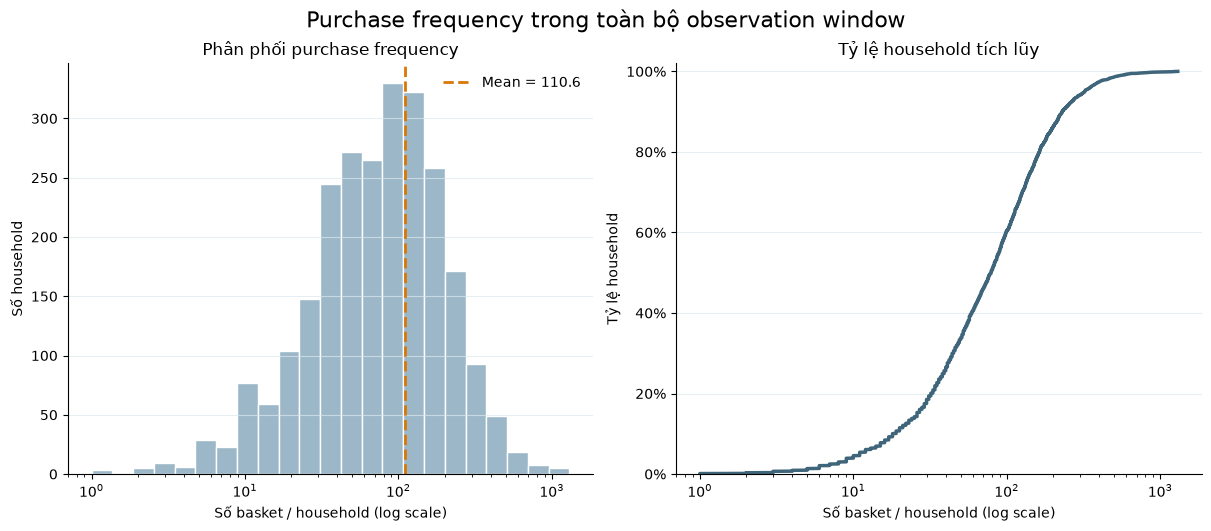

In [3]:
purchase_frequency_figure = plot_purchase_frequency(behavior.households)

## 3. Basket Size, Breadth, Category Penetration & Value

Bốn góc nhìn: (1) số product distinct kèm mean, (2) số department distinct, (3) basket penetration của các department từ 10% trở lên và nhóm `Other`, (4) histogram `customer spend / basket` kèm mean; 5% basket cao nhất được gom vào overflow bin `> p95`.

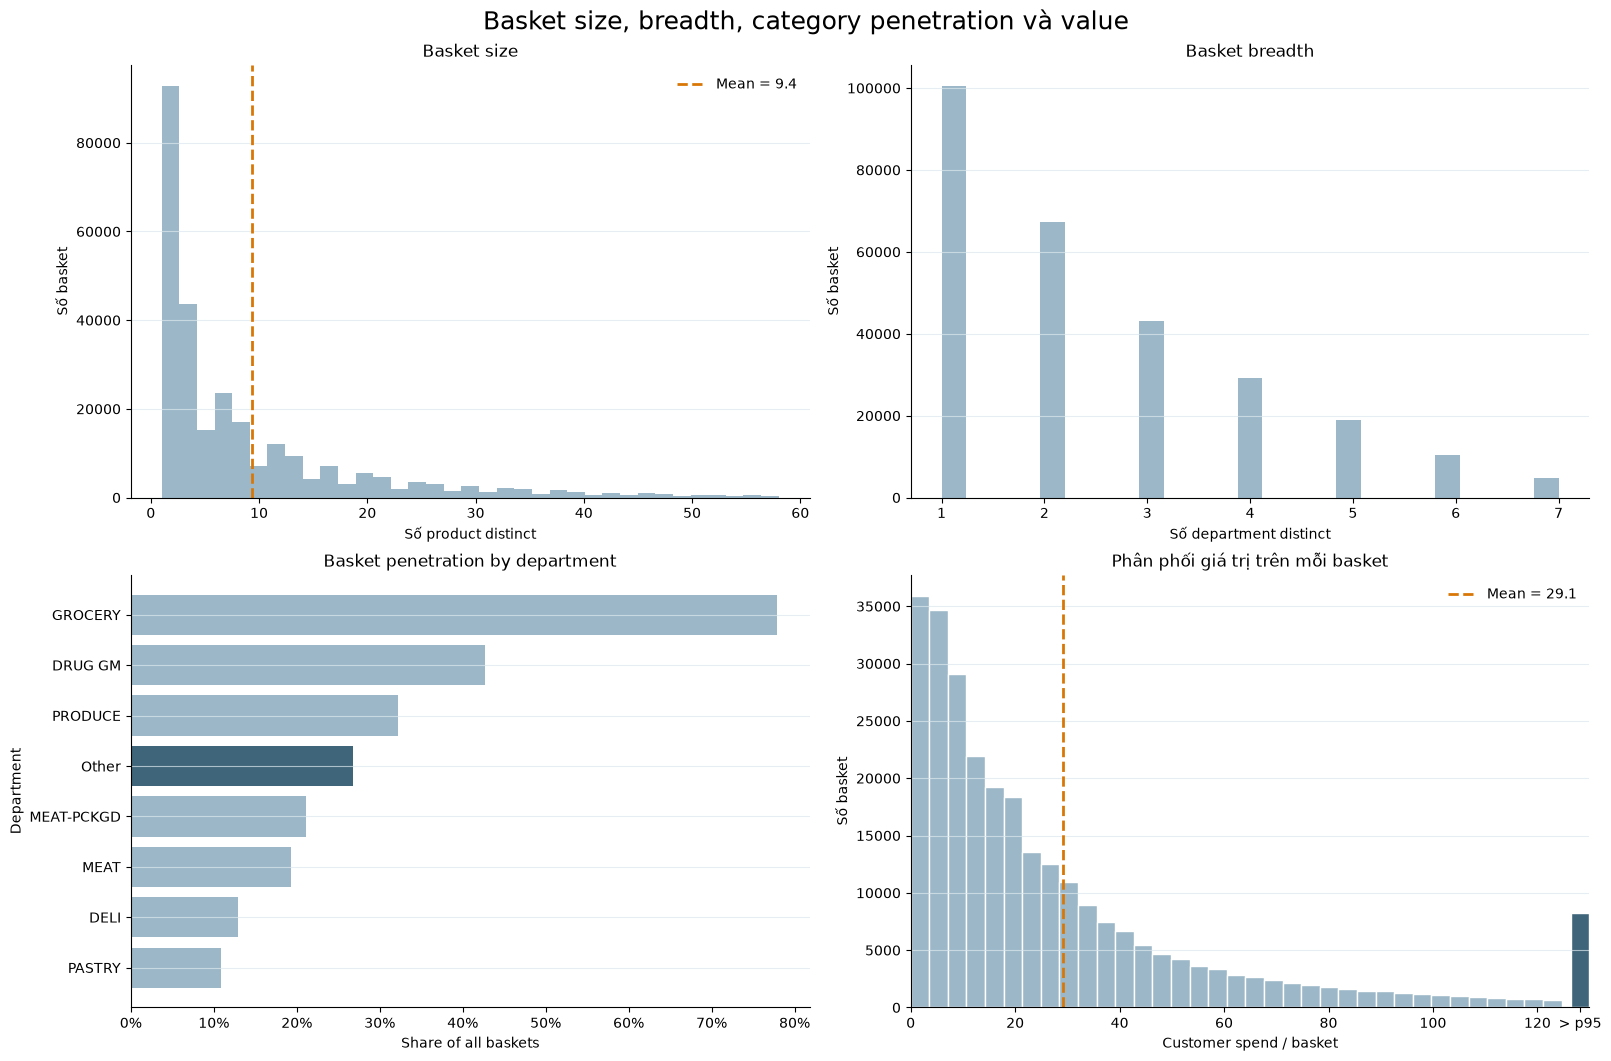

In [4]:
basket_figure = plot_basket_size_value_structure(
    behavior.baskets,
    behavior.category_penetration,
)

- Basket trung bình 9.4 sản phẩm, nhưng đại đa số giỏ hàng rất nhỏ, chỉ một nhóm nhỏ mua nhiều.
- Phần lớn chuyến mua hàng chỉ gói gọn trong 1–3 ngành hàng.
- GROCERY xuất hiện ở 78% giỏ hàng, các ngành hàng khác chiếm tỷ lệ rất thấp.

## 4. Household Spending

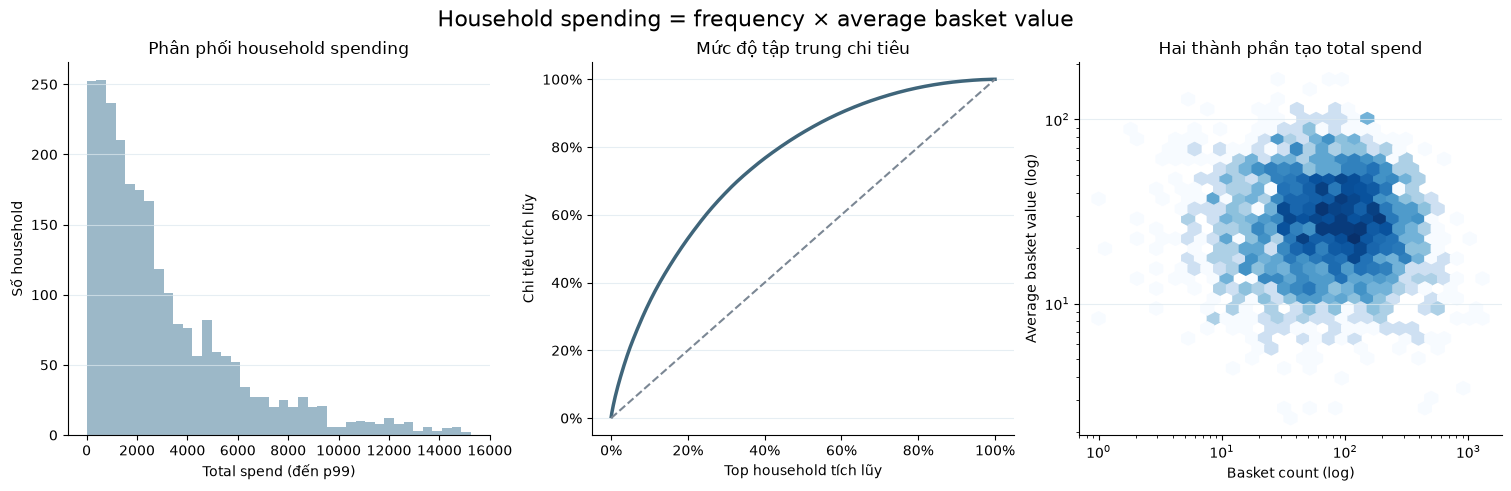

In [5]:
household_spending_figure = plot_household_spending(behavior.households)

- 20% khách hàng đóng góp tới 50% chi tiêu tích lũy
- Khách hàng chi tiêu cao thuộc nhiều loại khách hàng

## 5. Store Usage

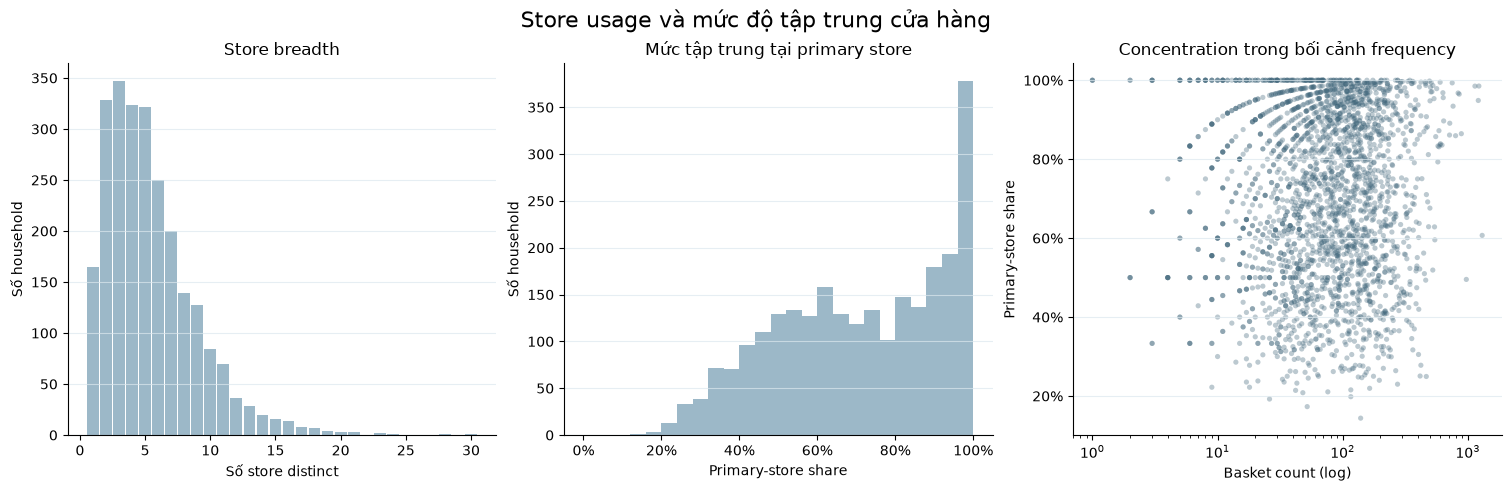

In [6]:
store_usage_figure = plot_store_usage(behavior.households)

## 6. Transaction Discount Usage

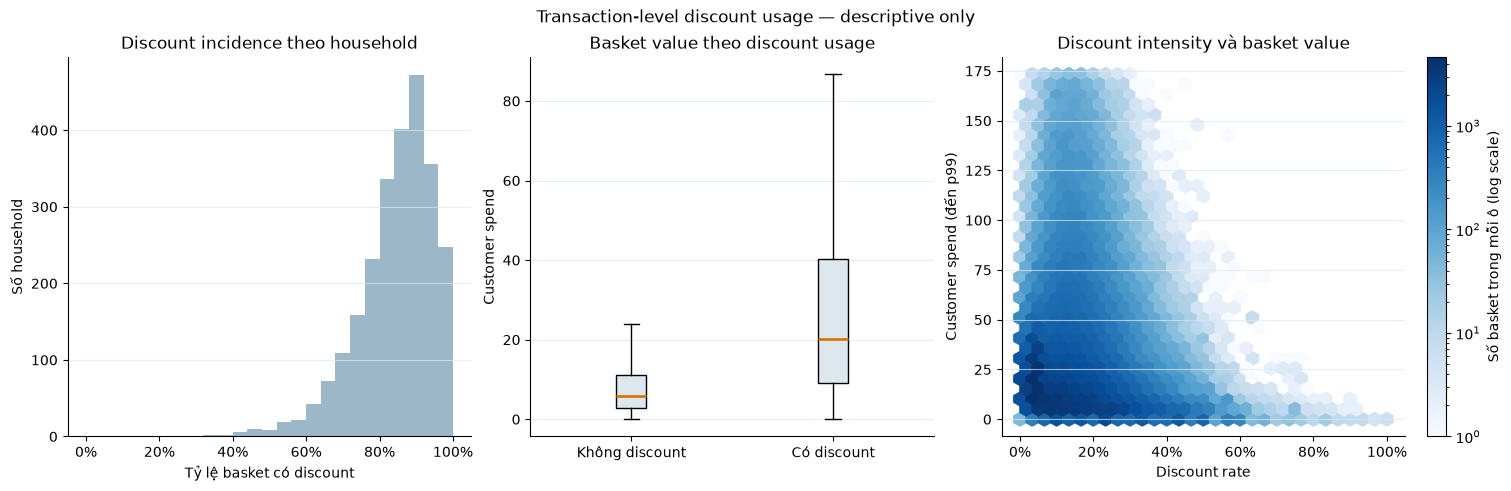

In [7]:
discount_usage_figure = plot_transaction_discount_usage(
    behavior.baskets,
    behavior.households,
)

- Phần lớn household có khoảng 80–95% basket chứa ít nhất một hình thức discount.
- Basket có discount thường có customer spend cao hơn basket không discount.
- Biểu đồ cho thấy các basket có discount sâu và giá trị cao tương đối hiếm. Phần lớn basket tập trung ở discount rate dưới 40% và customer spend dưới khoảng 70.

## 7. Cross-Behavior Analysis

Spearman correlation phù hợp hơn Pearson cho các behavioral metrics lệch mạnh. Heatmap dùng để nhận diện trục hành vi liên hệ hoặc dư thừa; correlation không chứng minh quan hệ nhân quả.

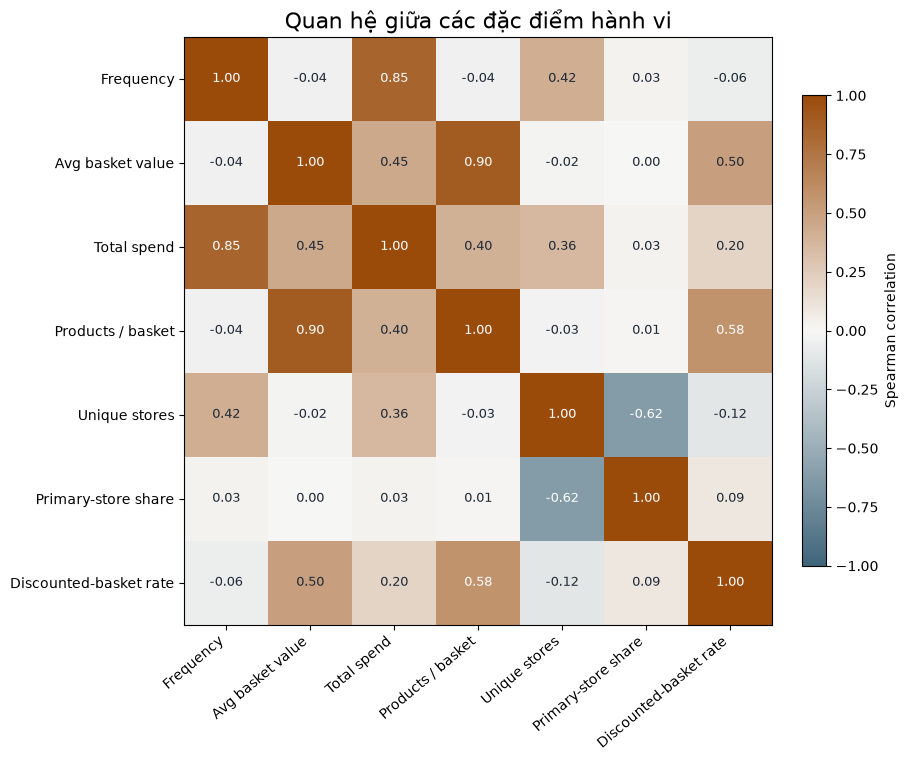

In [8]:
cross_behavior_figure = plot_cross_behavior(behavior.households)

## 8. Behavioral Patterns & Insights

Bốn quadrant frequency × average basket value tạo các pattern mô tả dễ đọc. Đây chưa phải segmentation cuối cùng: chưa kết hợp temporal behavior của file 04, category/promotion behavior của file 05 hoặc kiểm tra độ ổn định theo snapshot.

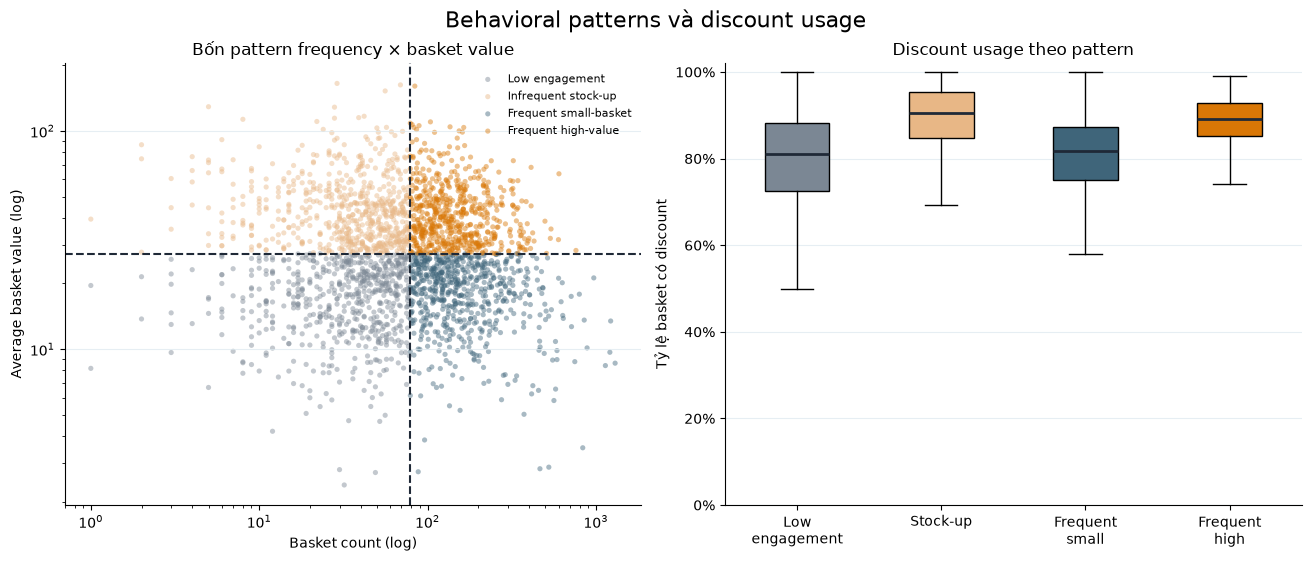

In [9]:
behavioral_patterns_figure = plot_behavioral_patterns(behavior.households)